In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import time
import seaborn as sns
from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import SelectFromModel, SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score, accuracy_score

# Selección de Características y Entrenamiento.

## a)

In [ ]:
DataSet = 'processed.cleveland.data'
Columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
DataFrame = pd.read_csv(DataSet, names=Columns)
def high_or_low(num):
  if num >= 2:
    return 1
  else:
    return 0
DataFrame['class'] = DataFrame['num'].apply(high_or_low)
DataFrame = DataFrame.drop('num', axis=1)
DataFrame = DataFrame.replace('?', np.nan)
DataFrame = DataFrame.dropna()

## b)

In [ ]:
X = DataFrame.drop('class', axis=1)
y = DataFrame['class']
TrainRatio = 0.6
TestRatio = 0.2
ValidationRatio = 0.2
XTrain, XTemporary, yTrain, yTemporary = train_test_split(X, y, test_size=1-TrainRatio, random_state=3, stratify=y)
XValidation, XTest, yValidation, yTest = train_test_split(XTemporary, yTemporary, test_size=0.5, random_state=3, stratify=yTemporary)

## c)

In [ ]:
Scaler = StandardScaler()
Scaler.fit(XTrain)
XTrainNormalized = Scaler.transform(XTrain)
XValidationNormalized = Scaler.transform(XValidation)
XTestNormalized = Scaler.transform(XTest)

## d)

In [ ]:
Indexs = np.zeros(len(XTrainNormalized) + len(XValidationNormalized))
Indexs[:len(XTrainNormalized)] = -1
PreDefinedSplit = PredefinedSplit(test_fold=Indexs)
ParametersGrid1 = {'C': [0.01, 0.1, 1, 10, 100]}
SVM = SVC(kernel='linear')
GridSearch0 = GridSearchCV(estimator=SVM, param_grid=ParametersGrid1, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch0.fit(np.vstack((XTrainNormalized, XValidationNormalized)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestSVM0 = GridSearch0.best_estimator_
BestSVM0.fit(XTrainNormalized, yTrain)
TrainingTime0 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime0}')
print(f'Mejor SVM: {BestSVM0}')

Tiempo de entrenamiento: 0.44524049758911133
Mejor SVM: SVC(C=0.01, kernel='linear')


## e)

Accuracy del mejor SVM sobre el conjunto de validación: 0.8813559322033898


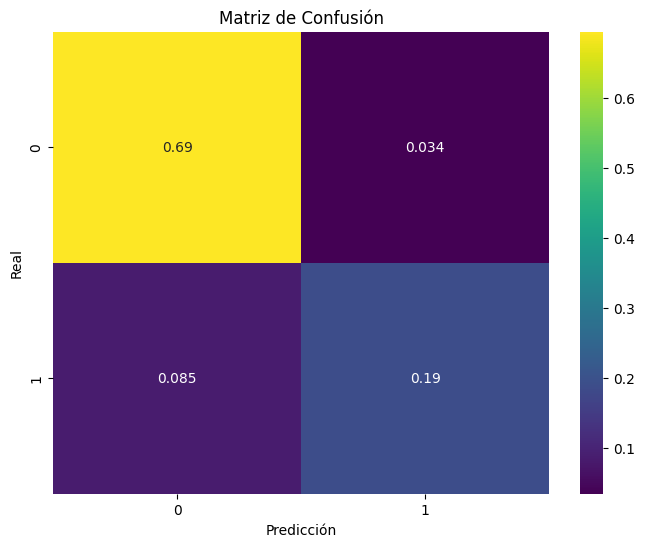

In [ ]:
yPredictedValidation = BestSVM0.predict(XValidationNormalized)
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation, normalize='all')
ValidationScore0 = accuracy_score(yPredictedValidation, yValidation)
print(f'Accuracy del mejor SVM sobre el conjunto de validación: {ValidationScore0}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## f)

In [ ]:
Selector1 = SelectFromModel(BestSVM0)
SelectedFeatures1 = X.columns[Selector1.get_support()]
print('Las features seleccionadas por SelectFromModel son:')
for i, Feature in enumerate(SelectedFeatures1):
  print(f'{i+1} {Feature}')

Las features seleccionadas por SelectFromModel son:
1 cp
2 thalach
3 oldpeak
4 ca
5 thal


## g)

Tiempo de entrenamiento: 0.04792594909667969
Mejor SVM: SVC(C=0.1, kernel='linear')
Accuracy del mejor SVM sobre el conjunto de validación: 0.847457627118644


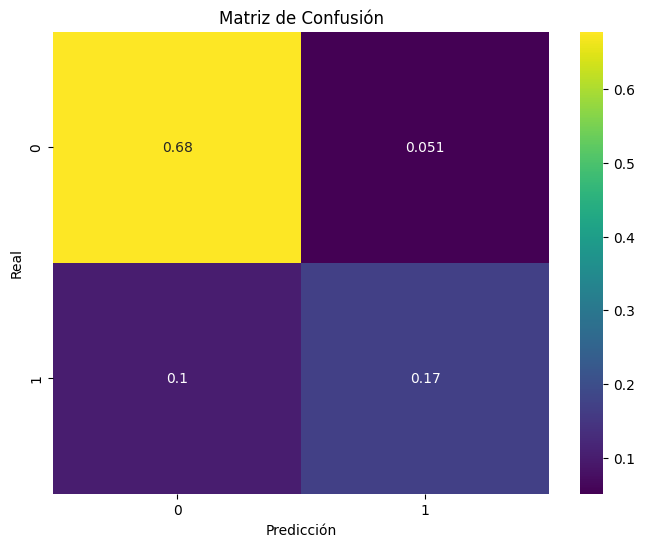

In [ ]:
XTrainNormalizedSelected1 = Selector1.transform(XTrainNormalized)
XValidationNormalizedSelected1 = Selector1.transform(XValidationNormalized)
GridSearch1 = GridSearchCV(estimator=SVM, param_grid=ParametersGrid1, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch1.fit(np.vstack((XTrainNormalizedSelected1, XValidationNormalizedSelected1)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestSVM1 = GridSearch1.best_estimator_
TrainingTime1 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime1}')
print(f'Mejor SVM: {BestSVM1}')
BestSVM1.fit(XTrainNormalizedSelected1, yTrain)
yPredictedValidation1 = BestSVM1.predict(XValidationNormalizedSelected1)
Labels = [0, 1]
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation1, normalize='all')
ValidationScore1 = accuracy_score(yPredictedValidation1, yValidation)
print(f'Accuracy del mejor SVM sobre el conjunto de validación: {ValidationScore1}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## h)

Tiempo de entrenamiento: 0.035726308822631836
Mejor SVM: SVC(C=0.01, kernel='linear')
Accuracy del mejor SVM sobre el conjunto de validación: 0.8813559322033898
Las features seleccionadas por SelectKBest (6) son:
1 sex
2 thalach
3 exang
4 oldpeak
5 ca
6 thal


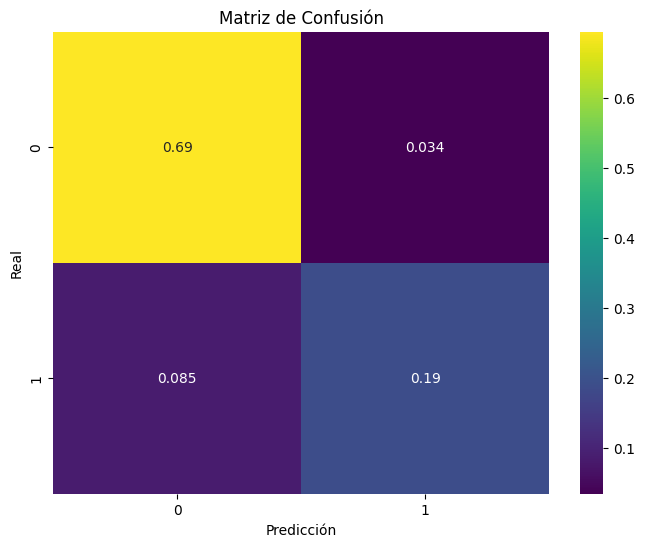

In [ ]:
Selector2 = SelectKBest(f_classif, k=6)
XTrainNormalizedSelected2 = Selector2.fit_transform(XTrainNormalized, yTrain)
XValidationNormalizedSelected2 = Selector2.fit_transform(XValidationNormalized, yValidation)
GridSearch2 = GridSearchCV(estimator=SVM, param_grid=ParametersGrid1, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch2.fit(np.vstack((XTrainNormalizedSelected2, XValidationNormalizedSelected2)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestSVM2 = GridSearch2.best_estimator_
TrainingTime2 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime2}')
print(f'Mejor SVM: {BestSVM2}')
BestSVM2.fit(XTrainNormalizedSelected2, yTrain)
yPredictedValidation2 = BestSVM2.predict(XValidationNormalizedSelected2)
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation2, normalize='all')
ValidationScore2 = accuracy_score(yPredictedValidation2, yValidation)
print(f'Accuracy del mejor SVM sobre el conjunto de validación: {ValidationScore2}')
SelectedFeatures2 = X.columns[Selector2.get_support()]
print('Las features seleccionadas por SelectKBest (6) son:')
for i, Feature in enumerate(SelectedFeatures2):
  print(f'{i+1} {Feature}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## i)

Tiempo de entrenamiento: 0.02878403663635254
Mejor SVM: SVC(C=0.1, kernel='linear')
Accuracy del mejor SVM sobre el conjunto de validación: 0.864406779661017
Las features seleccionadas por SelectKBest (3) son:
1 exang
2 oldpeak
3 ca


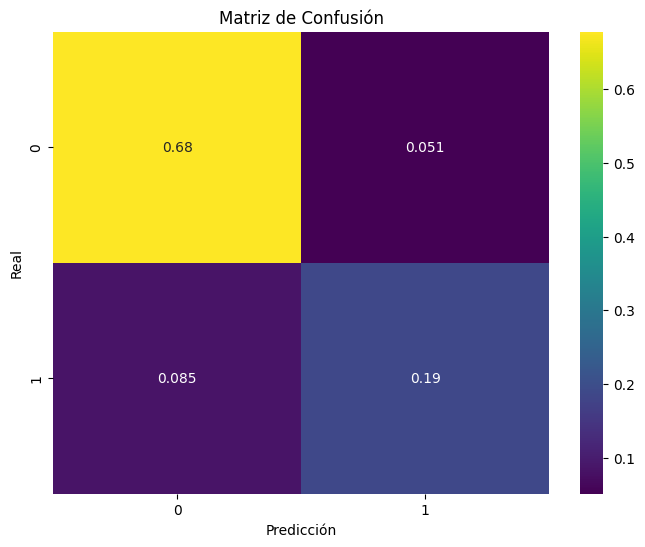

In [ ]:
Selector3 = SelectKBest(f_classif, k=3)
XTrainNormalizedSelected3 = Selector3.fit_transform(XTrainNormalized, yTrain)
XValidationNormalizedSelected3 = Selector3.fit_transform(XValidationNormalized, yValidation)
GridSearch3 = GridSearchCV(estimator=SVM, param_grid=ParametersGrid1, cv=PreDefinedSplit)
InitialTrainingTime= time.time()
GridSearch3.fit(np.vstack((XTrainNormalizedSelected3, XValidationNormalizedSelected3)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestSVM3 = GridSearch3.best_estimator_
TrainingTime3 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime3}')
print(f'Mejor SVM: {BestSVM3}')
BestSVM3.fit(XTrainNormalizedSelected3, yTrain)
yPredictedValidation3 = BestSVM3.predict(XValidationNormalizedSelected3)
Labels = [0, 1]
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation3, normalize='all')
ValidationScore3 = accuracy_score(yPredictedValidation3, yValidation)
print(f'Accuracy del mejor SVM sobre el conjunto de validación: {ValidationScore3}')
SelectedFeatures3 = X.columns[Selector3.get_support()]
print('Las features seleccionadas por SelectKBest (3) son:')
for i, Feature in enumerate(SelectedFeatures3):
  print(f'{i+1} {Feature}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## j)

Tiempo de entrenamiento: 1.4202051162719727
Mejor RandomForest: RandomForestClassifier (max_depth=8, n_estimators=100)
Accuracy del mejor Random Forest sobre el conjunto de validación: 0.847457627118644


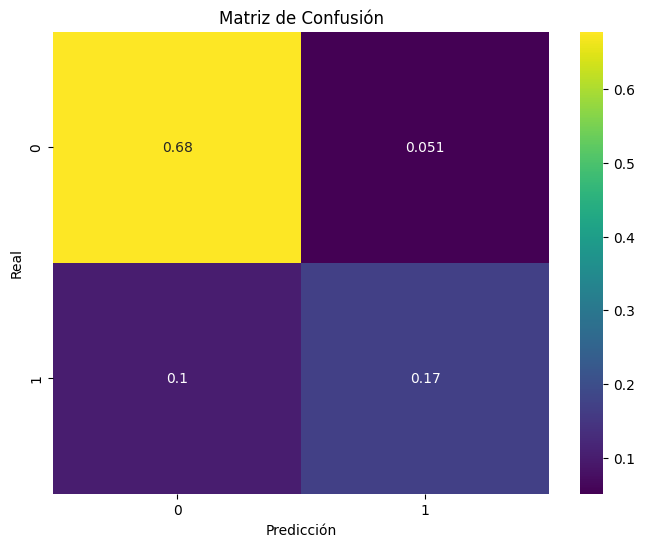

In [ ]:
RandomForest = RandomForestClassifier(max_depth=8, random_state=3)
ParametersGrid2 = {'n_estimators': [50, 100, 150, 200, 250]}
GridSearch4 = GridSearchCV(RandomForest, param_grid=ParametersGrid2, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch4.fit(np.vstack((XTrainNormalized, XValidationNormalized)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestRandomForest0 = GridSearch4.best_estimator_
TrainingTime4 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime4}')
print(f'Mejor RandomForest: RandomForestClassifier (max_depth={BestRandomForest0.max_depth}, n_estimators={BestRandomForest0.n_estimators})')
BestRandomForest0.fit(XTrainNormalized, yTrain)
yPredictedValidation4 = BestRandomForest0.predict(XValidationNormalized)
Labels = [0, 1]
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation4, normalize='all')
ValidationScore4 = accuracy_score(yPredictedValidation4, yValidation)
print(f'Accuracy del mejor Random Forest sobre el conjunto de validación: {ValidationScore4}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## k)

Tiempo de entrenamiento: 1.4190337657928467
Mejor RandomForest: RandomForestClassifier (max_depth=8, n_estimators=150)
Accuracy del mejor RandomForest sobre el conjunto de validación: 0.7966101694915254
Las features seleccionadas por SelectFromModel son:
1 age
2 trestbps
3 chol
4 thalach
5 oldpeak
6 ca


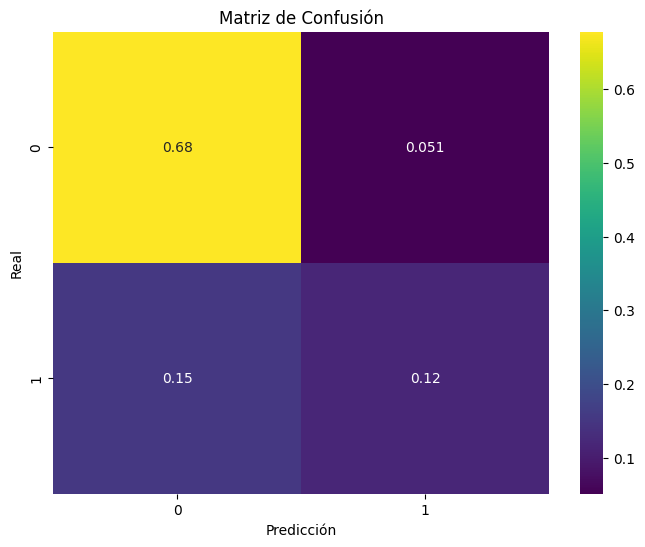

In [ ]:
Selector4 = SelectFromModel(BestRandomForest0)
XTrainNormalizedSelected4 = Selector4.transform(XTrainNormalized)
XValidationNormalizedSelected4 = Selector4.transform(XValidationNormalized)
GridSearch5 = GridSearchCV(RandomForest, param_grid=ParametersGrid2, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch5.fit(np.vstack((XTrainNormalizedSelected4, XValidationNormalizedSelected4)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestRandomForest1 = GridSearch5.best_estimator_
TrainingTime5 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime5}')
print(f'Mejor RandomForest: RandomForestClassifier (max_depth={BestRandomForest1.max_depth}, n_estimators={BestRandomForest1.n_estimators})')
BestRandomForest1.fit(XTrainNormalizedSelected4, yTrain)
yPredictedValidation5 = BestRandomForest1.predict(XValidationNormalizedSelected4)
Labels = [0, 1]
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation5, normalize='all')
ValidationScore5 = accuracy_score(yPredictedValidation5, yValidation)
print(f'Accuracy del mejor RandomForest sobre el conjunto de validación: {ValidationScore5}')
SelectedFeatures4 = X.columns[Selector4.get_support()]
print('Las features seleccionadas por SelectFromModel son:')
for i, Feature in enumerate(SelectedFeatures4):
  print(f'{i+1} {Feature}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## l)

Tiempo de entrenamiento: 1.4290881156921387
Mejor RandomForest: RandomForestClassifier (max_depth=8, n_estimators=50)
Accuracy del mejor RandomForest sobre el conjunto de validación: 0.864406779661017
Las features seleccionadas por SelectKBest (6) son: 
1 sex
2 thalach
3 exang
4 oldpeak
5 ca
6 thal


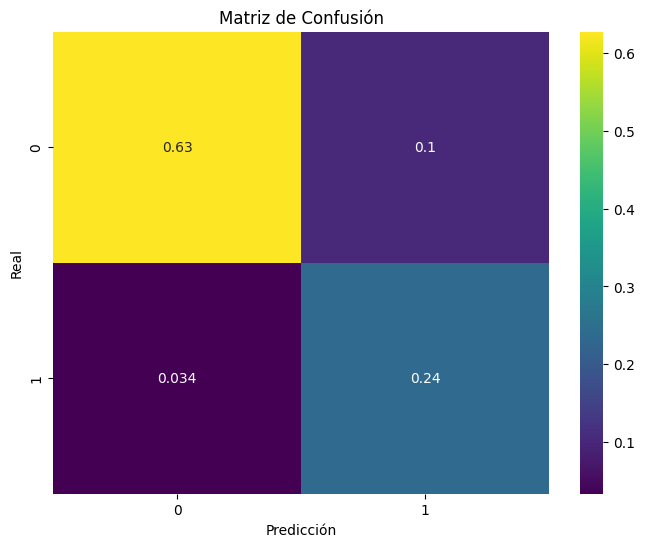

In [ ]:
Selector5 = SelectKBest(f_classif, k=6)
XTrainNormalizedSelected5 = Selector5.fit_transform(XTrainNormalized, yTrain)
XValidationNormalizedSelected5 = Selector5.fit_transform(XValidationNormalized, yValidation)
GridSearch6 = GridSearchCV(RandomForest, param_grid=ParametersGrid2, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch6.fit(np.vstack((XTrainNormalizedSelected5, XValidationNormalizedSelected5)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestRandomForest2 = GridSearch6.best_estimator_
TrainingTime6 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime6}')
print(f'Mejor RandomForest: RandomForestClassifier (max_depth={BestRandomForest2.max_depth}, n_estimators={BestRandomForest2.n_estimators})')
BestRandomForest2.fit(XTrainNormalizedSelected5, yTrain)
yPredictedValidation6 = BestRandomForest2.predict(XValidationNormalizedSelected5)
Labels = [0, 1]
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation6, normalize='all')
ValidationScore6 = accuracy_score(yPredictedValidation6, yValidation)
print(f'Accuracy del mejor RandomForest sobre el conjunto de validación: {ValidationScore6}')
SelectedFeatures5 = X.columns[Selector5.get_support()]
print('Las features seleccionadas por SelectKBest (6) son: ')
for i, Feature in enumerate(SelectedFeatures5):
  print(f'{i+1} {Feature}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## m)

Tiempo de entrenamiento: 2.105545997619629
Mejor RandomForest: RandomForestClassifier (max_depth=8, n_estimators=100)
Accuracy del mejor SVM sobre el conjunto de validación: 0.7966101694915254
1 exang
2 oldpeak
3 ca


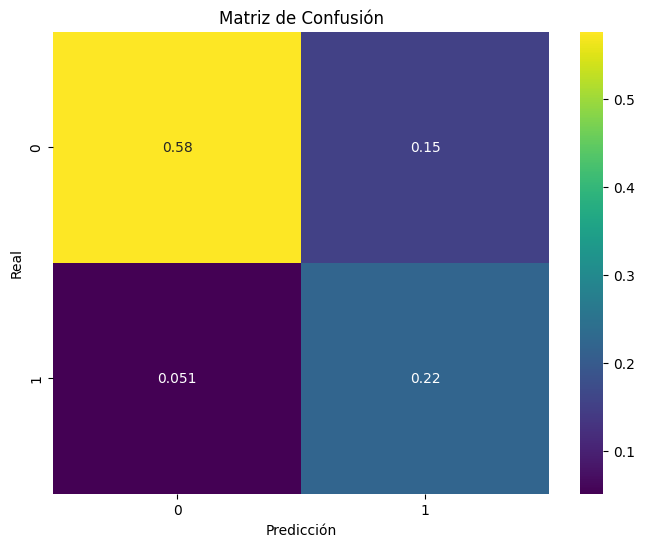

In [ ]:
Selector6 = SelectKBest(f_classif, k=3)
XTrainNormalizedSelected6 = Selector6.fit_transform(XTrainNormalized, yTrain)
XValidationNormalizedSelected6 = Selector6.fit_transform(XValidationNormalized, yValidation)
GridSearch7 = GridSearchCV(RandomForest, param_grid=ParametersGrid2, cv=PreDefinedSplit)
InitialTrainingTime = time.time()
GridSearch7.fit(np.vstack((XTrainNormalizedSelected6, XValidationNormalizedSelected6)), np.hstack((yTrain, yValidation)))
FinalTrainingTime = time.time()
BestRandomForest3 = GridSearch7.best_estimator_
BestScore = GridSearch7.best_score_
TrainingTime7 = FinalTrainingTime - InitialTrainingTime
print(f'Tiempo de entrenamiento: {TrainingTime7}')
print(f'Mejor RandomForest: RandomForestClassifier (max_depth={BestRandomForest3.max_depth}, n_estimators={BestRandomForest3.n_estimators})')
BestRandomForest3.fit(XTrainNormalizedSelected6, yTrain)
yPredictedValidation7 = BestRandomForest3.predict(XValidationNormalizedSelected6)
ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation7, normalize='all')
ValidationScore7 = accuracy_score(yPredictedValidation7, yValidation)
print(f'Accuracy del mejor SVM sobre el conjunto de validación: {ValidationScore7}')
SelectedFeatures6 = X.columns[Selector6.get_support()]
for i, Feature in enumerate(SelectedFeatures6):
  print(f'{i+1} {Feature}')
plt.figure(figsize=(8,6))
sns.heatmap(ConfusionMatrix, annot=True, cmap=plt.cm.viridis)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## n)

Accuracy del mejor SVM sobre el conjunto de prueba: 0.8833333333333333
Accuracy del mejor RandomForest sobre el conjunto de prueba: 0.75


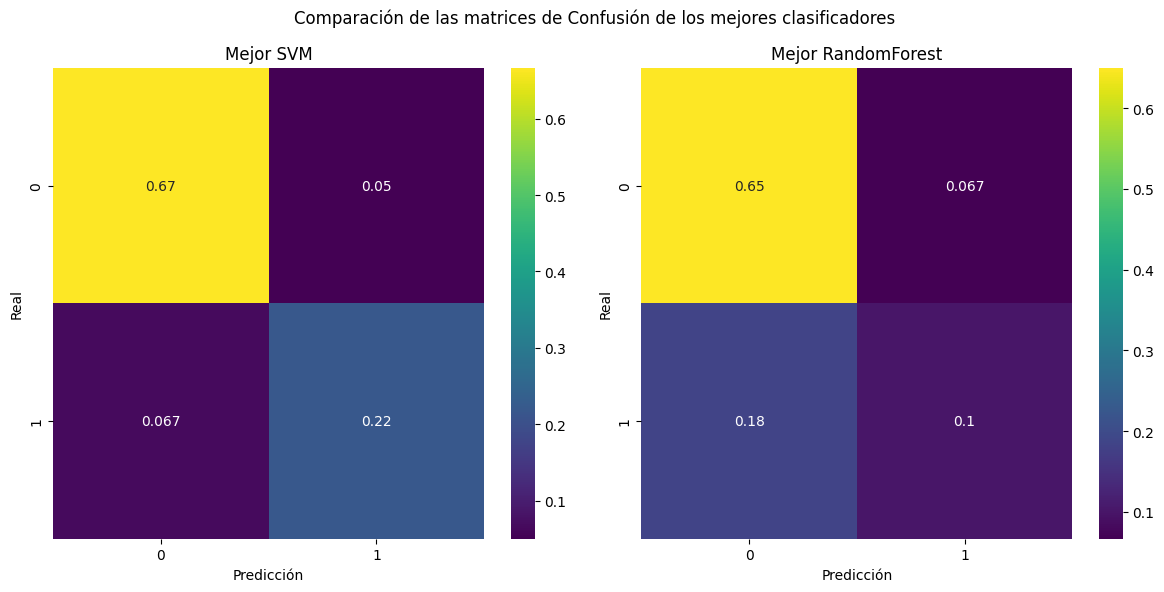

In [ ]:
BestSVM = BestSVM1
BestRandomForest = BestRandomForest2
XTestNormalizedScaled1 = Selector1.transform(XTestNormalized)
XTestNormalizedScaled2 = Selector4.transform(XTestNormalized)
Labels = [0, 1]
yPredictedTest1 = BestSVM.predict(XTestNormalizedScaled1)
ConfusionMatrix1 = confusion_matrix(yTest, yPredictedTest1, normalize='all')
TestScore1 = accuracy_score(yPredictedTest1, yTest)
print(f'Accuracy del mejor SVM sobre el conjunto de prueba: {TestScore1}')
yPredictedTest2 = BestRandomForest.predict(XTestNormalizedScaled2)
ConfusionMatrix2 = confusion_matrix(yTest, yPredictedTest2, normalize='all')
TestScore2 = accuracy_score(yPredictedTest2, yTest)
print(f'Accuracy del mejor RandomForest sobre el conjunto de prueba: {TestScore2}')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Comparación de las matrices de Confusión de los mejores clasificadores')
ax1 = sns.heatmap(ConfusionMatrix1, annot=True, cmap=plt.cm.viridis, ax=ax1)
ax1.set_title('Mejor SVM')
ax1.set_xlabel('Predicción')
ax1.set_ylabel('Real')
ax2 = sns.heatmap(ConfusionMatrix2, annot=True, cmap=plt.cm.viridis, ax=ax2)
ax2.set_title('Mejor RandomForest')
ax2.set_xlabel('Predicción')
ax2.set_ylabel('Real')
plt.tight_layout()
plt.show()

# Análisis


## a)

## b)

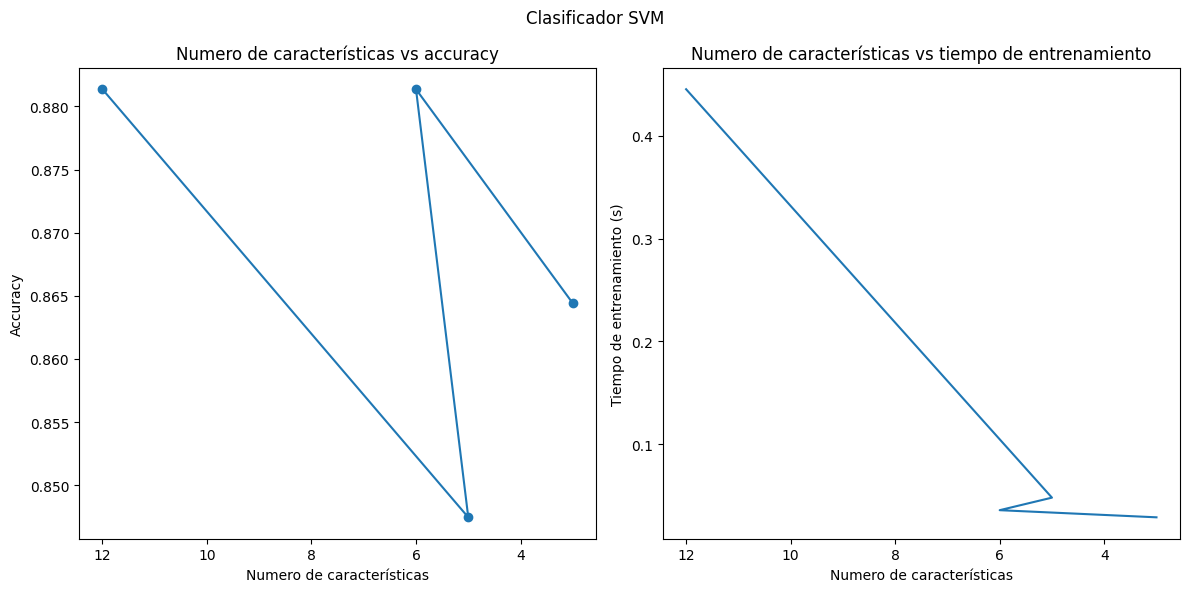

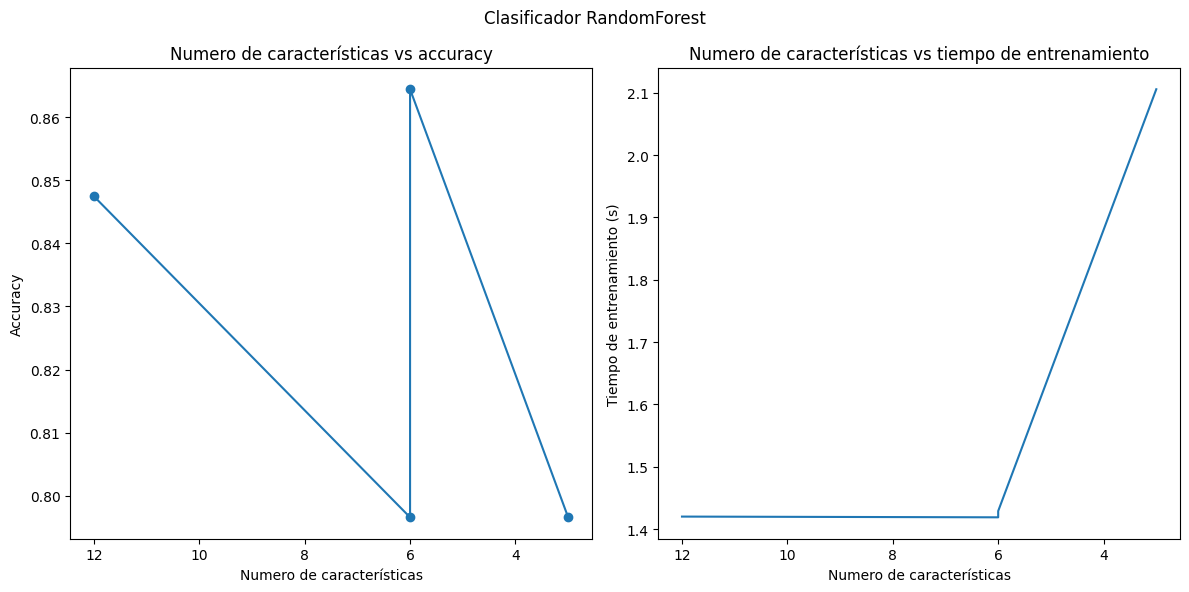

In [ ]:
NumberOfFeaturesSVM = [12, 5, 6, 3]
NumberOfFeaturesRandomForest = [12, 6, 6, 3]
TrainingTimesSVM = [TrainingTime0, TrainingTime1, TrainingTime2, TrainingTime3]
TrainingTimesRandomForest = [TrainingTime4, TrainingTime5, TrainingTime6, TrainingTime7]
AccuracysSVM = [ValidationScore0, ValidationScore1, ValidationScore2, ValidationScore3]
AccuracysRandomForest = [ValidationScore4, ValidationScore5, ValidationScore6, ValidationScore7]
plt.subplots(1, 2, figsize=(12, 6))
plt.suptitle('Clasificador SVM')
plt.subplot(1, 2, 1)
plt.title('Numero de características vs accuracy')
plt.plot(NumberOfFeaturesSVM, AccuracysSVM, marker='o')
plt.xlabel('Numero de características')
plt.ylabel('Accuracy')
plt.gca().invert_xaxis()
plt.subplot(1, 2, 2)
plt.title('Numero de características vs tiempo de entrenamiento')
plt.plot(NumberOfFeaturesSVM, TrainingTimesSVM)
plt.xlabel('Numero de características')
plt.ylabel('Tiempo de entrenamiento (s)')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()
plt.subplots(1, 2, figsize=(12, 6))
plt.suptitle('Clasificador RandomForest')
plt.subplot(1, 2, 1)
plt.title('Numero de características vs accuracy')
plt.plot(NumberOfFeaturesRandomForest, AccuracysRandomForest, marker='o')
plt.xlabel('Numero de características')
plt.ylabel('Accuracy')
plt.gca().invert_xaxis()
plt.subplot(1, 2, 2)
plt.title('Numero de características vs tiempo de entrenamiento')
plt.plot(NumberOfFeaturesRandomForest, TrainingTimesRandomForest)
plt.xlabel('Numero de características')
plt.ylabel('Tiempo de entrenamiento (s)')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

## c)

In [ ]:
AccuracysSVMMaxIndex = AccuracysSVM.index(max(AccuracysSVM))
TrainingTimesSVMMinIndex = TrainingTimesSVM.index(min(TrainingTimesSVM))
NumberOfFeaturesSVMMaxAccuracy = NumberOfFeaturesSVM[AccuracysSVMMaxIndex]
NumberOfFeaturesSVMMinTime = NumberOfFeaturesSVM[TrainingTimesSVMMinIndex]
AccuracysRandomForestMaxIndex = AccuracysRandomForest.index(max(AccuracysRandomForest))
TrainingTimesRandomForestMinIndex = TrainingTimesRandomForest.index(min(TrainingTimesRandomForest))
NumberOfFeaturesRandomForestMaxAccuracy = NumberOfFeaturesSVM[AccuracysRandomForestMaxIndex]
NumberOfFeaturesRandomForestMinTime = NumberOfFeaturesSVM[TrainingTimesRandomForestMinIndex]
print(f'Para los clasificadores SVM, el mayor valor de Accuracy se obtiene con {NumberOfFeaturesSVMMaxAccuracy} caraterísticas y el menor tiempo de entrenamiento se obtiene con {NumberOfFeaturesSVMMinTime} caraterísticas.')
print(f'Para los clasificadores RandomForest, el mayor valor de Accuracy se obtiene con {NumberOfFeaturesRandomForestMaxAccuracy} caraterísticas y el menor tiempo de entrenamiento se obtiene con {NumberOfFeaturesRandomForestMinTime} caraterísticas.')
print('Como el mayor valor de Accuracy se obtiene con las características originales, se puede afirmar que para dicho caso no es beneficioso la selección de características.')
print('Como el mayor valor de Accuracy y el menor tiempo de entrenamiento, para los clasificadores Random Forest, se obtiene con 6 características, se puede afirmar que para dicho caso es beneficioso la selección de características.')

Para los clasificadores SVM, el mayor valor de Accuracy se obtiene con 12 caraterísticas y el menor tiempo de entrenamiento se obtiene con 3 caraterísticas.
Para los clasificadores RandomForest, el mayor valor de Accuracy se obtiene con 6 caraterísticas y el menor tiempo de entrenamiento se obtiene con 6 caraterísticas.
Como el mayor valor de Accuracy se obtiene con las características originales, se puede afirmar que para dicho caso no es beneficioso la selección de características.
Como el mayor valor de Accuracy y el menor tiempo de entrenamiento, para los clasificadores Random Forest, se obtiene con 6 características, se puede afirmar que para dicho caso es beneficioso la selección de características.
